In [2]:
!apt-get update
!apt-get install -y libopencv-dev build-essential cmake

Hit:1 https://cli.github.com/packages stable InRelease
Get:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Hit:3 http://archive.ubuntu.com/ubuntu noble InRelease
Get:4 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:5 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:6 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:7 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:9 https://r2u.stat.illinois.edu/ubuntu noble/main amd64 Packages [3,054 kB]
Get:10 http://archive.ubuntu.com/ubuntu noble-updates/multiverse amd64 Packages [67.4 kB]
Get:11 http://archive.ubuntu.com/ubuntu noble-updates/universe amd64 Packages [2,166 kB]
Get:12 http://archive.ubuntu.com/ubuntu noble-updates/main amd64 Packages [1,701 kB]
Get:13 http://archive.ubuntu.com/ubuntu noble-updates/restricted amd64 Packages [2,17

In [13]:
%%writefile main.cpp
#include <iostream>
#include <opencv2/opencv.hpp>
#include <cuda_runtime.h>

int main() {
    std::cout << "OpenCV Versiyonu: " << CV_VERSION << std::endl;

    // Colab GPU Bağlantı Kontrolü
    int deviceCount = 0;
    cudaError_t error = cudaGetDeviceCount(&deviceCount);

    if (error == cudaSuccess && deviceCount > 0) {
        std::cout << "Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: " << deviceCount << std::endl;
    } else {
        std::cout << "CUDA Cihazı Bulunamadı veya GPU Aktif Edilmedi!" << std::endl;
    }

    return 0;
}

Overwriting main.cpp


In [14]:
!g++ main.cpp -o app pkg-config --cflags --libs opencv4 -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart
!./app

g++: error: unrecognized command-line option ‘--cflags’
g++: error: unrecognized command-line option ‘--libs’; did you mean ‘--libs=’?
/bin/bash: line 1: ./app: Permission denied


In [27]:
%%writefile log_processing.cpp
#include <iostream>
#include <opencv2/opencv.hpp>

void applyLoG(const std::string& imagePath, const std::string& outputPrefix) {
    // 1. Görüntüyü gri tonlamalı olarak yükle
    cv::Mat src = cv::imread(imagePath, cv::IMREAD_GRAYSCALE);
    if (src.empty()) {
        std::cerr << "Hata: Resim yuklenemedi! Yol: " << imagePath << std::endl;
        return;
    }

    // 2. Doğrudan Laplacian (Gauss Yumuşatması Uygulanmamış)
    cv::Mat raw_laplacian_16S, raw_laplacian_abs;
    cv::Laplacian(src, raw_laplacian_16S, CV_16S, 7);
    cv::convertScaleAbs(raw_laplacian_16S, raw_laplacian_abs);

    // 3. Gauss Filtresi Uygula (7x7 Boyutunda Yumuşatma)
    cv::Mat blurred;
    cv::GaussianBlur(src, blurred, cv::Size(7, 7), 0, 0);

    // 4. Yumuşatılmış Görüntüye Laplacian Uygula (Laplacian of Gaussian - LoG)
    cv::Mat log_16S, log_abs;
    cv::Laplacian(blurred, log_16S, CV_16S, 7);
    cv::convertScaleAbs(log_16S, log_abs);

    // 5. Sonuçları disk üzerine kaydet
    cv::imwrite(outputPrefix + "_original.jpg", src);
    cv::imwrite(outputPrefix + "_raw_laplacian.jpg", raw_laplacian_abs);
    cv::imwrite(outputPrefix + "_log.jpg", log_abs);

    std::cout << imagePath << " icin LoG islemleri tamamlandi." << std::endl;
}

int main() {
    std::cout << "--- LoG Filtreleme Baslatiliyor ---" << std::endl;
    applyLoG("/content/foto1", "foto1");
    applyLoG("/content/foto2", "foto2");
    std::cout << "--- Tum Islemler Tamamlandi ---" << std::endl;
    return 0;
}

Overwriting log_processing.cpp


In [28]:
# C++ Kodunu derle ve çalıştır
!g++ log_processing.cpp -o log_app `pkg-config --cflags --libs opencv4`
!chmod +x ./log_app
!./log_app

--- LoG Filtreleme Baslatiliyor ---
/content/foto1 icin LoG islemleri tamamlandi.
/content/foto2 icin LoG islemleri tamamlandi.
--- Tum Islemler Tamamlandi ---


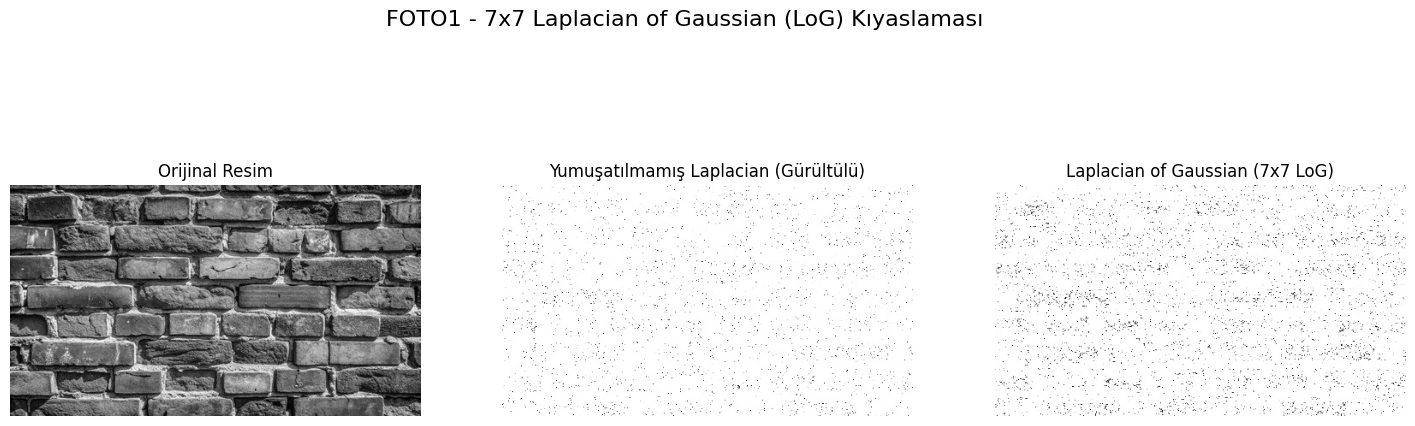

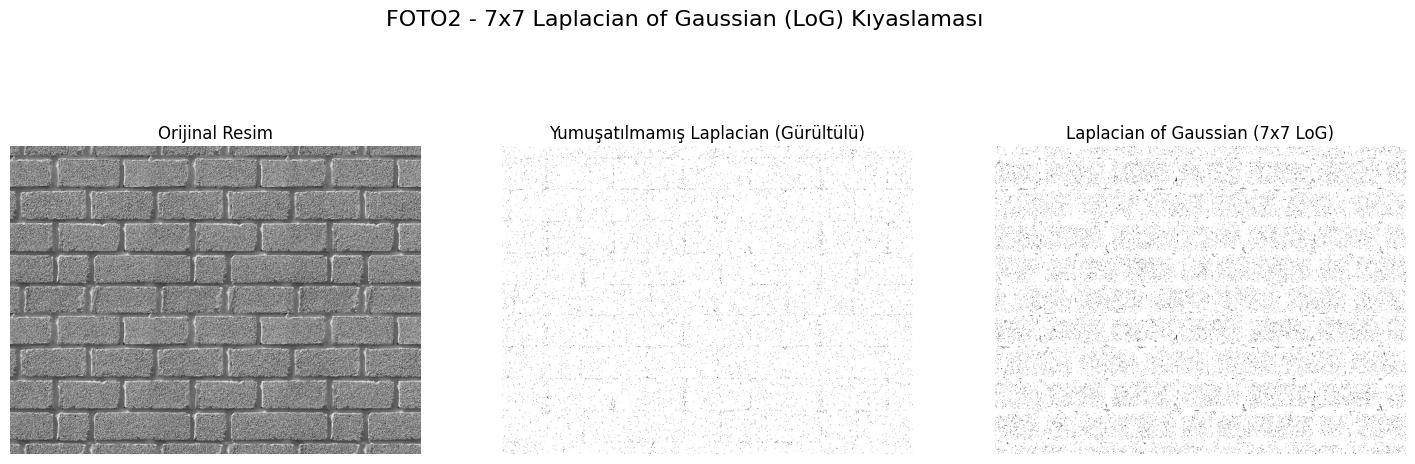

In [29]:
import cv2
import matplotlib.pyplot as plt
import os

def display_log_results(prefix):
    files = [
        f'{prefix}_original.jpg',
        f'{prefix}_raw_laplacian.jpg',
        f'{prefix}_log.jpg'
    ]

    for f in files:
        if not os.path.exists(f):
            print(f"Hata: '{f}' dosyası bulunamadı.")
            return

    original = cv2.imread(f'{prefix}_original.jpg', cv2.IMREAD_GRAYSCALE)
    raw_lap = cv2.imread(f'{prefix}_raw_laplacian.jpg', cv2.IMREAD_GRAYSCALE)
    log_img = cv2.imread(f'{prefix}_log.jpg', cv2.IMREAD_GRAYSCALE)

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    axes[0].imshow(original, cmap='gray')
    axes[0].set_title('Orijinal Resim')
    axes[0].axis('off')

    axes[1].imshow(raw_lap, cmap='gray')
    axes[1].set_title('Yumuşatılmamış Laplacian (Gürültülü)')
    axes[1].axis('off')

    axes[2].imshow(log_img, cmap='gray')
    axes[2].set_title('Laplacian of Gaussian (7x7 LoG)')
    axes[2].axis('off')

    plt.suptitle(f'{prefix.upper()} - 7x7 Laplacian of Gaussian (LoG) Kıyaslaması', fontsize=16)
    plt.show()

display_log_results('foto1')
display_log_results('foto2')